# 02b — Exploración

Bloques 3–5 del cuaderno 02: EDA, PCA meteorológico y virulencia. Solo visualización, sin escrituras.

## Imports (celda única del cuaderno)

In [1]:
# Imports del cuaderno (celda única) — todas las dependencias aquí; las demás celdas no importan nada.
from IPython.display import display
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from wildfire.config import load_config
from wildfire.data.io import load_csv
from wildfire.processing.pca_weather import fit_weather_pca, load_target_variance


# 3 — Análisis exploratorio de datos

### 3.1 — Temporalidad y estacionalidad

Restaura el datetime, deriva el mes y dibuja la estacionalidad.

str


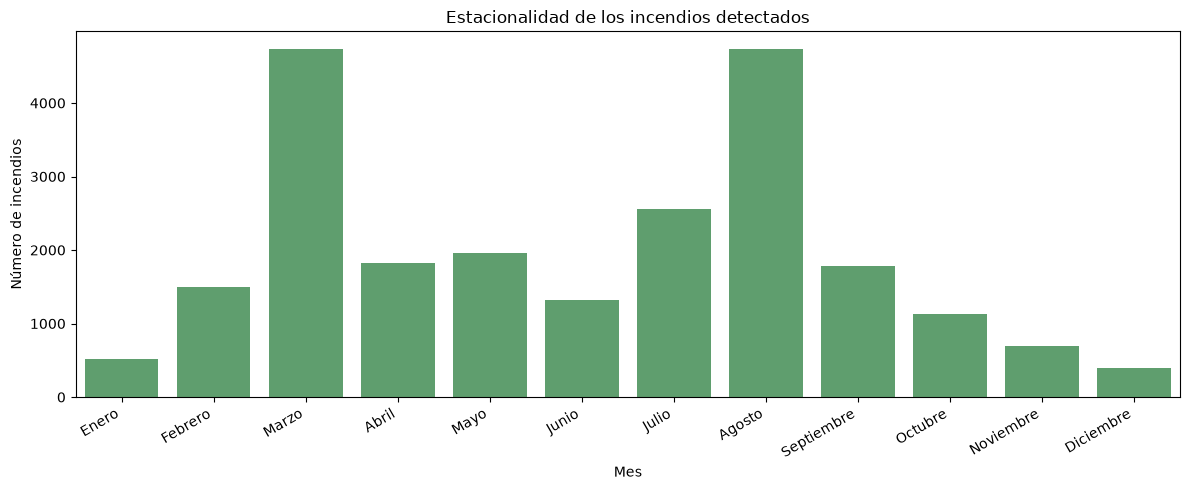

(23142, 61)
latitude                   0
longitude                  0
brightness                 0
scan                       0
acq_date                   0
                          ..
indice_riesgo_meteo_log    0
indice_meteorologico       0
componentes_disponibles    0
nivel_relativo             0
month_name                 0
Length: 61, dtype: int64


In [2]:

df = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")

print(df["acq_date"].dtype)

# 1. Restauración de las variables temporales borradas
df['acq_date'] = pd.to_datetime(df['acq_date'])
df["month"] = df["acq_date"].dt.month
month_names = {
    1: "Enero", 2: "Febrero", 3: "Marzo", 4: "Abril",
    5: "Mayo", 6: "Junio", 7: "Julio", 8: "Agosto",
    9: "Septiembre", 10: "Octubre", 11: "Noviembre", 12: "Diciembre",
}
df["month_name"] = df["month"].map(month_names)

# 2. Estacionalidad: número de detecciones positivas por mes
month_order = list(month_names.values())

plt.figure(figsize=(12, 5))
sns.countplot(
    data=df.dropna(subset=["month_name"]),
    x="month_name",
    order=month_order,
    color="#55A868",
)
plt.title("Estacionalidad de los incendios detectados")
plt.xlabel("Mes")
plt.ylabel("Número de incendios")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print(df.shape)
print(df.isna().sum())


Lo que ves: el tipo de la fecha antes de convertirla, la curva anual de detecciones (picos de verano y un repunte invernal del norte: quemas), y el tamaño más los huecos del dataset. Primera lectura: el fuego en España tiene dos temporadas distintas, y eso condicionará todos los grupos que busquemos después.

## Analisis exploratorio de las variables numericas

Esta seccion identifica automaticamente las columnas numericas de `firms_spain_final.csv`. Los valores ausentes se reportan y se ignoran solo en los estadisticos que lo requieren; no se imputan para no alterar la distribucion observada.


### 3.2 — Clima, correlación y termodinámica

Histogramas de 6 variables, matriz de Pearson, KDE y scatter temperatura×viento×FRP.

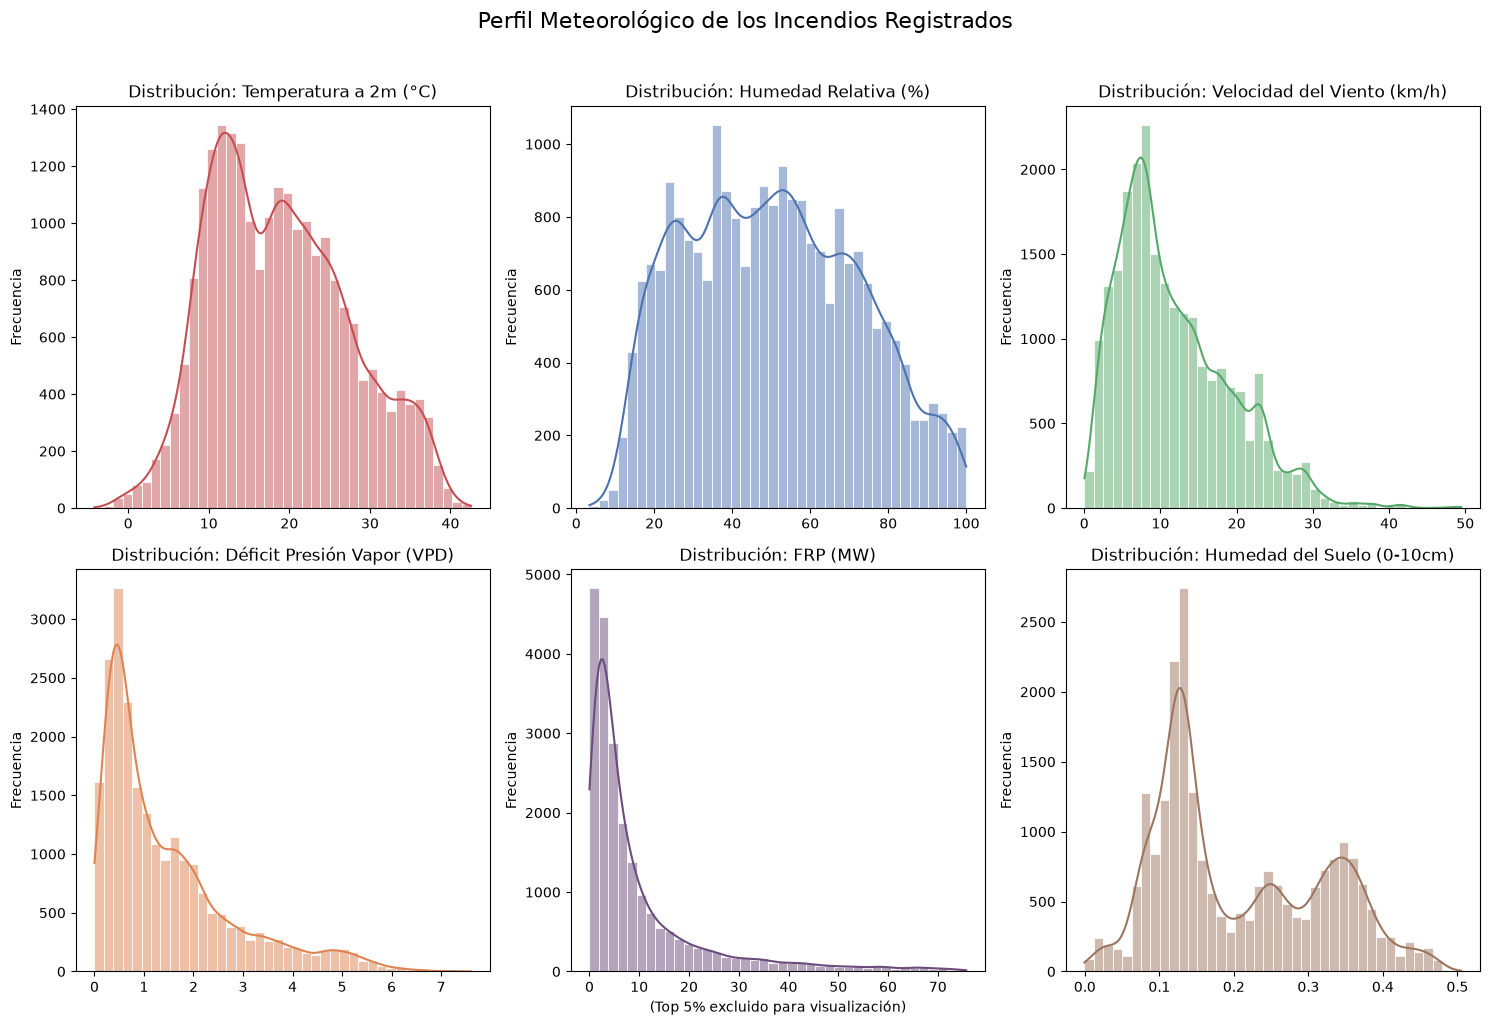

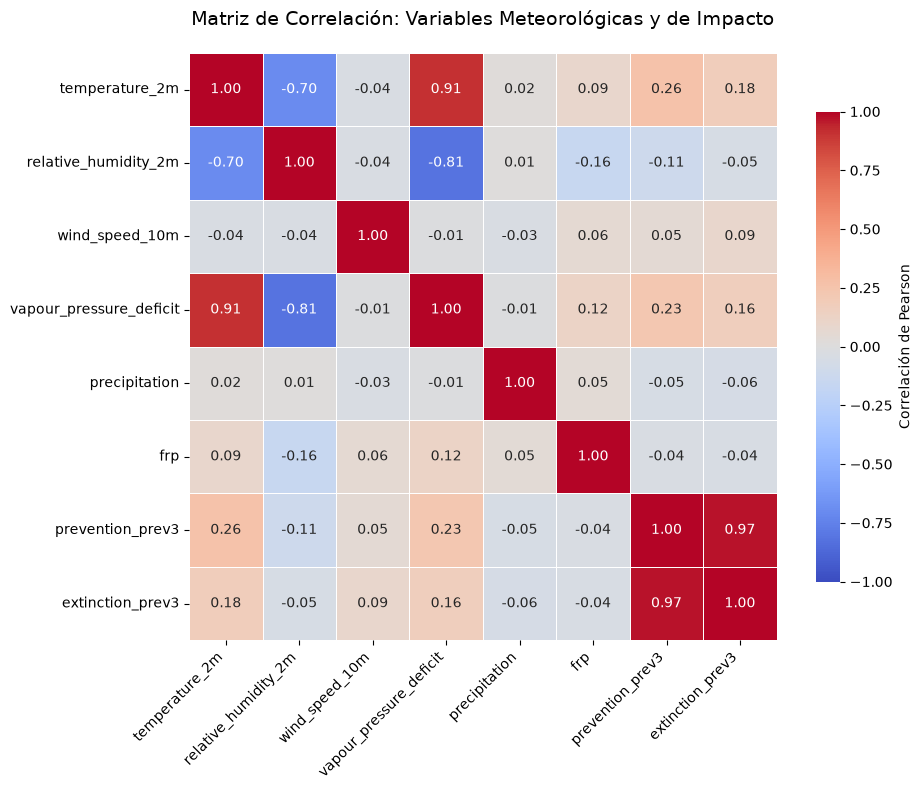

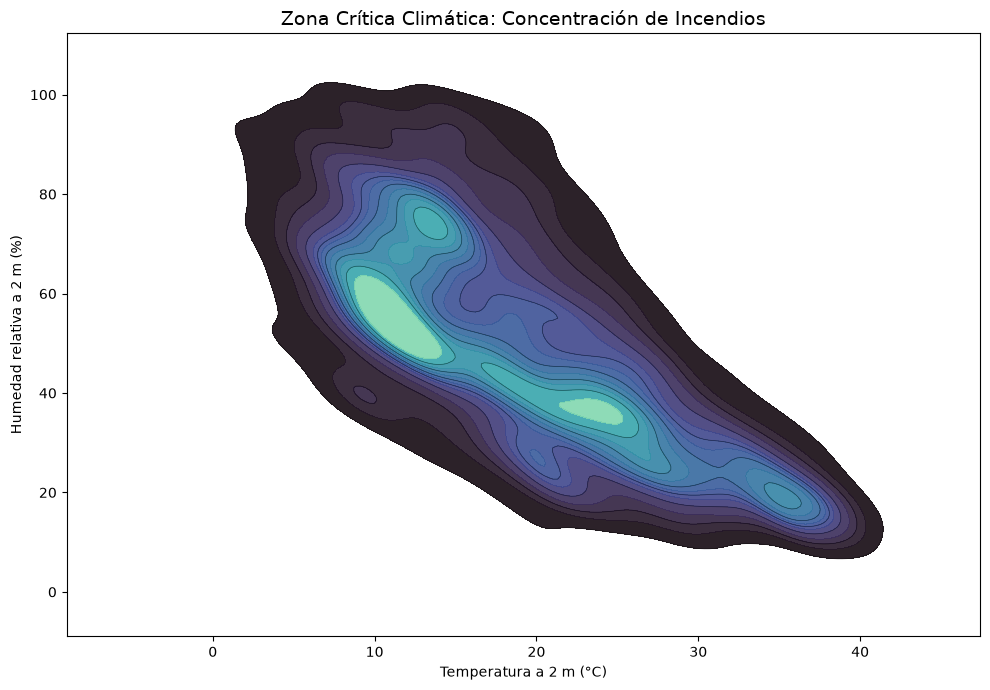

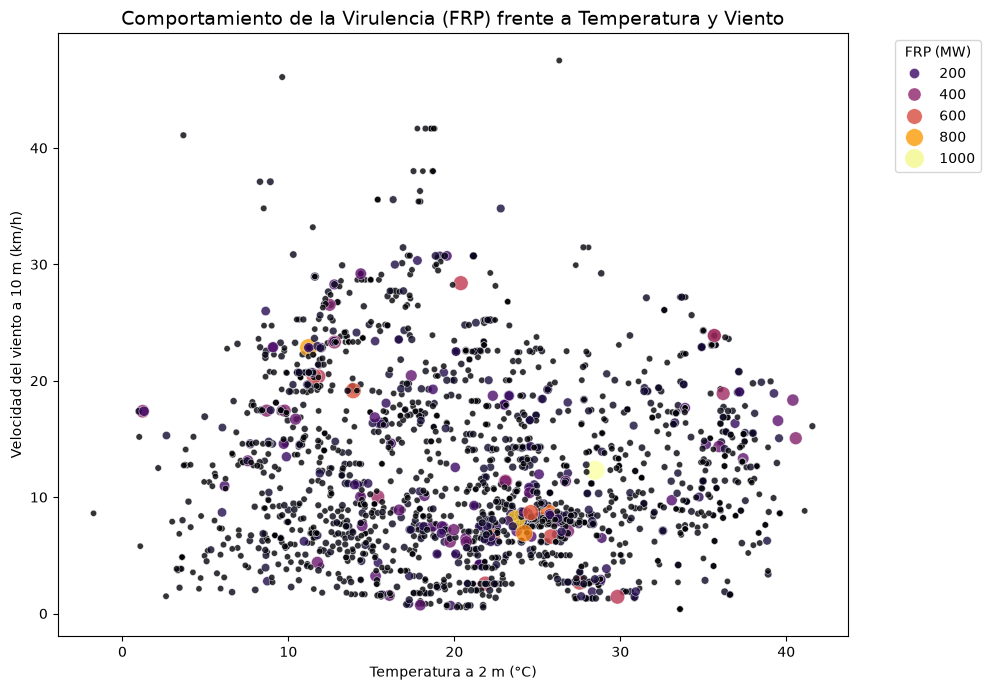

In [ ]:

# ============================================================
# 2. Distribución Climática Simplificada (Solo variables clave)
# ============================================================
# En lugar de dibujar 30 gráficos ilegibles, nos centramos en los 4 motores del fuego
key_climate_cols = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "vapour_pressure_deficit", "frp", "soil_moisture_0_to_7cm"]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
colors = ["#C44E52", "#4C72B0", "#55A868", "#DD8452", "#6B4C7D", "#9C755F"]
titles = ["Temperatura a 2m (°C)", "Humedad Relativa (%)", "Velocidad del Viento (km/h)", "Déficit Presión Vapor (VPD)", "FRP (MW)", "Humedad del Suelo (0-10cm)"]

for ax, col, color, title in zip(axes.flatten(), key_climate_cols, colors, titles):
    # Aplicamos un filtro del percentil 95 solo a las variables hiper-asimétricas
    if col in ["frp", "precipitation"]:
        p95 = df[col].quantile(0.95)
        data_to_plot = df[df[col] <= p95]
        sns.histplot(data=data_to_plot, x=col, kde=True, ax=ax, color=color, edgecolor="white", bins=40)
        ax.set_xlabel("(Top 5% excluido para visualización)")
    else:
        sns.histplot(data=df, x=col, kde=True, ax=ax, color=color, edgecolor="white", bins=40)
        ax.set_xlabel("")
        
    ax.set_title(f"Distribución: {title}", fontsize=12)
    ax.set_ylabel("Frecuencia")
fig.suptitle("Perfil Meteorológico de los Incendios Registrados", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


# ============================================================
# 3. Matriz de Correlación Curada (Sin ruido de variables)
# ============================================================
# Seleccionamos estrictamente lo que aporta valor al tribunal
num_years = load_config()["ccaa"]["budget_lookback_years"]

cols_to_correlate = [
    "temperature_2m", "relative_humidity_2m", "wind_speed_10m", 
    "vapour_pressure_deficit", "precipitation", "frp", 
    f"prevention_prev{num_years}", f"extinction_prev{num_years}"
]

corr_matrix = df[cols_to_correlate].corr(method="pearson")

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Correlación de Pearson"}
)

plt.title("Matriz de Correlación: Variables Meteorológicas y de Impacto", fontsize=14, pad=20)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# 4. Zona crítica climática (KDE Bivariante)
# ============================================================
plt.figure(figsize=(10, 7))

sns.kdeplot(
    data=df,
    x="temperature_2m",
    y="relative_humidity_2m",
    fill=True,
    levels=15,
    thresh=0.05,
    cmap="mako",
    alpha=0.9,
)

# Añadimos líneas de contorno para mayor claridad
sns.kdeplot(data=df, x="temperature_2m", y="relative_humidity_2m", levels=8, color="black", linewidths=0.5, alpha=0.5)

plt.title("Zona Crítica Climática: Concentración de Incendios", fontsize=14)
plt.xlabel("Temperatura a 2 m (°C)")
plt.ylabel("Humedad relativa a 2 m (%)")
plt.tight_layout()
plt.show()


# ============================================================
# 5. Tríada meteorológica (Viento vs Temperatura vs FRP)
# ============================================================
# Aplicamos un filtro para ver solo los incendios relevantes y no saturar la RAM
df_filtered = df[df["frp"] > 5].copy() 

sample_size = min(2000, len(df_filtered))
physical_sample = df_filtered.sample(n=sample_size, random_state=42)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(
    data=physical_sample,
    x="temperature_2m",
    y="wind_speed_10m",
    hue="frp",
    size="frp",
    sizes=(20, 200),
    palette="inferno",
    alpha=0.8,
    edgecolor="white"
)

plt.title("Comportamiento de la Virulencia (FRP) frente a Temperatura y Viento", fontsize=14)
plt.xlabel("Temperatura a 2 m (°C)")
plt.ylabel("Velocidad del viento a 10 m (km/h)")
plt.legend(title="FRP (MW)", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


En llano, figura a figura: (1) los histogramas enseñan la forma de cada variable — la lluvia es casi todo ceros con alguna tromba, el FRP igual (pocos fuegos fieros, muchos flojos); (2) el mapa de correlaciones dice qué variables se mueven juntas — calor, sequedad y ET0 suben a la vez; (3) temperatura contra humedad dibuja la física: calor↔seco, frío↔húmedo; (4) las burbujas grandes (FRP alto) viven arriba a la derecha: calor + viento. Conclusión: el peligro nace de una combinación, no de una sola variable.

**Lectura recomendada:** revisar primero las variables con mayor porcentaje de nulos y asimetria, despues los histogramas para detectar distribuciones no normales y finalmente las parejas con alta correlacion. Antes de modelar, las variables muy correlacionadas pueden requerir seleccion, transformacion o regularizacion.


# 4 — PCA meteorológico

Reducción de las 14 variables continuas en componentes; k por pca.target_variance en config.

### 4.1 — PCA de 14 variables

14 continuas + wd_sin/wd_cos; k por `pca.target_variance` en config. Exploratorio: no alimenta ningún modelo.

Features: 14
target_variance=0.9 -> k=7 componentes


,varianza,acumulada
PC1,0.351505,0.351505
PC2,0.148303,0.499808
PC3,0.133130,0.632938
PC4,0.085654,0.718592
PC5,0.078810,0.797402
PC6,0.063663,0.861065
PC7,0.054092,0.915157
PC8,0.029669,0.944826
PC9,0.022343,0.967169
PC10,0.017506,0.984675


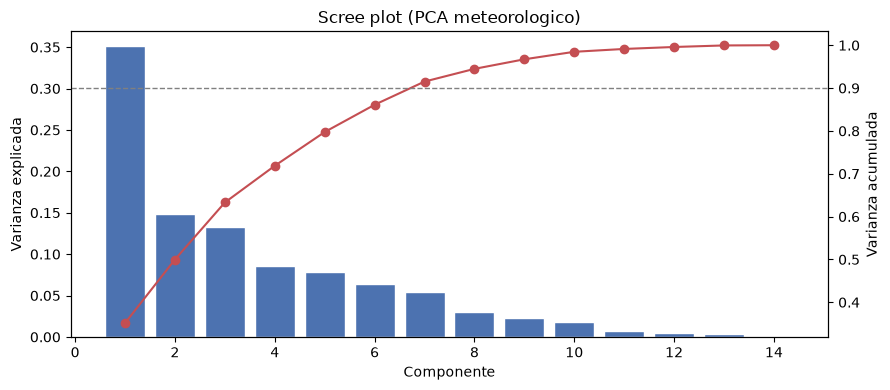


Cargas PC1 (ordenadas por |carga|):
vapour_pressure_deficit       0.917998
et0_fao_evapotranspiration    0.915979
temperature_2m                0.887521
relative_humidity_2m         -0.840521
shortwave_radiation           0.822368
boundary_layer_height         0.692294
soil_moisture_0_to_7cm       -0.515457
soil_moisture_7_to_28cm      -0.496480
surface_pressure              0.194607
wind_speed_10m                0.142079
wd_cos                        0.107749
wind_gusts_10m                0.080206
wd_sin                       -0.034540
precipitation                -0.018354


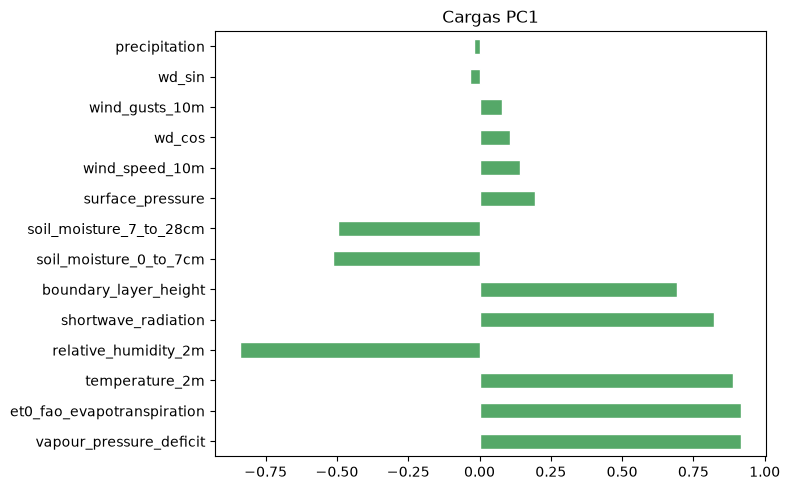


Cargas PC2 (ordenadas por |carga|):
wind_gusts_10m                0.848108
wind_speed_10m                0.803889
boundary_layer_height         0.456310
soil_moisture_7_to_28cm       0.443597
soil_moisture_0_to_7cm        0.412272
wd_sin                       -0.206415
temperature_2m               -0.171081
et0_fao_evapotranspiration    0.131979
shortwave_radiation           0.121225
surface_pressure              0.108627
vapour_pressure_deficit      -0.093810
relative_humidity_2m          0.083212
wd_cos                       -0.052084
precipitation                 0.040126


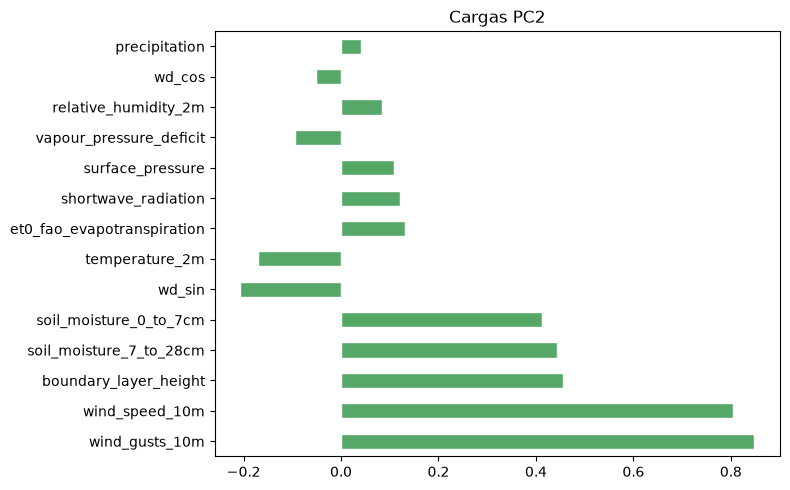


Cargas PC3 (ordenadas por |carga|):
soil_moisture_0_to_7cm        0.686595
soil_moisture_7_to_28cm       0.651729
wd_cos                       -0.554829
wind_speed_10m               -0.510229
wind_gusts_10m               -0.343885
shortwave_radiation           0.306120
et0_fao_evapotranspiration    0.230284
surface_pressure             -0.182664
vapour_pressure_deficit       0.172673
wd_sin                       -0.156693
boundary_layer_height         0.125227
precipitation                 0.115930
temperature_2m                0.106181
relative_humidity_2m         -0.080280


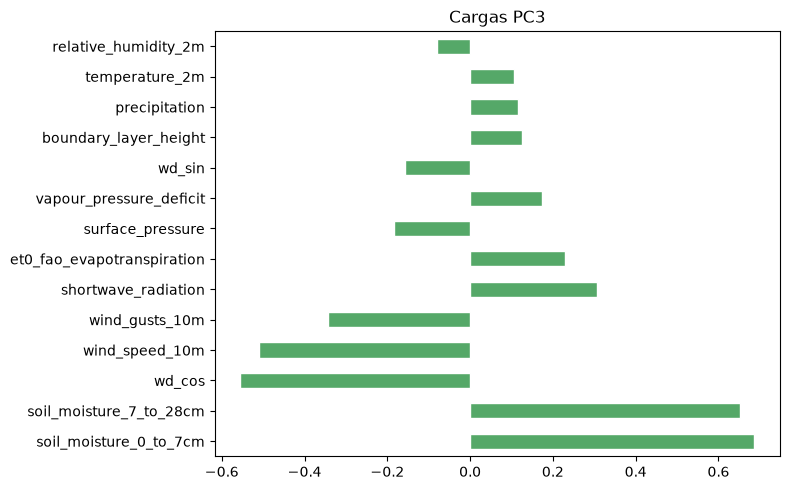


Cargas PC4 (ordenadas por |carga|):
surface_pressure              0.739836
precipitation                -0.543652
wd_sin                       -0.480033
wind_gusts_10m               -0.228270
shortwave_radiation          -0.138100
relative_humidity_2m          0.121128
temperature_2m                0.113287
et0_fao_evapotranspiration   -0.098536
boundary_layer_height         0.083219
wd_cos                       -0.072095
soil_moisture_7_to_28cm       0.050743
vapour_pressure_deficit       0.044992
soil_moisture_0_to_7cm        0.026749
wind_speed_10m                0.004930


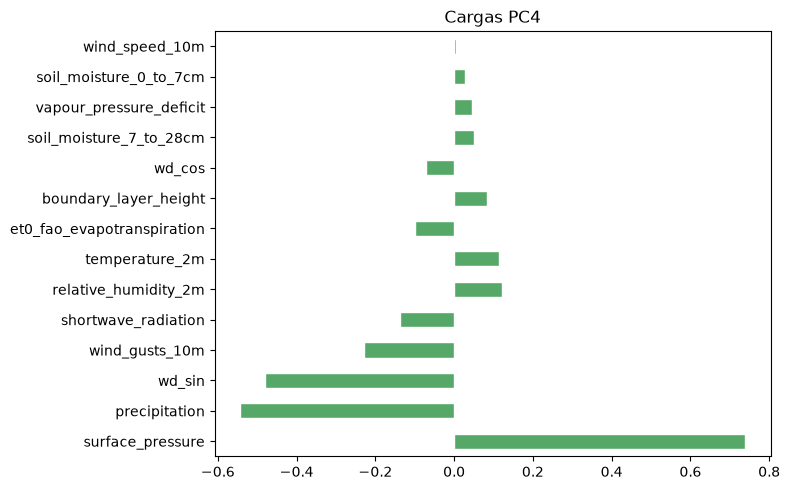


Cargas PC5 (ordenadas por |carga|):
wd_sin                        0.669212
wd_cos                        0.455801
precipitation                -0.439112
soil_moisture_7_to_28cm       0.270073
shortwave_radiation           0.245438
soil_moisture_0_to_7cm        0.184709
surface_pressure              0.180770
et0_fao_evapotranspiration    0.160904
wind_gusts_10m               -0.108735
temperature_2m               -0.106289
vapour_pressure_deficit      -0.067787
wind_speed_10m               -0.027582
relative_humidity_2m          0.024987
boundary_layer_height         0.001500


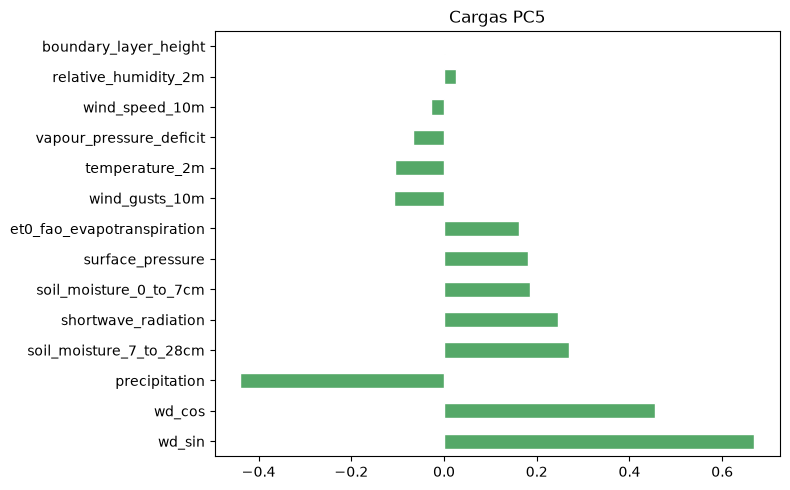


Cargas PC6 (ordenadas por |carga|):
precipitation                 0.693573
surface_pressure              0.458461
wd_cos                        0.330132
relative_humidity_2m          0.182742
wind_gusts_10m               -0.170679
soil_moisture_0_to_7cm        0.090926
shortwave_radiation           0.078814
vapour_pressure_deficit      -0.063343
boundary_layer_height         0.058147
temperature_2m                0.044020
et0_fao_evapotranspiration    0.043868
soil_moisture_7_to_28cm       0.039185
wind_speed_10m               -0.034842
wd_sin                       -0.009508


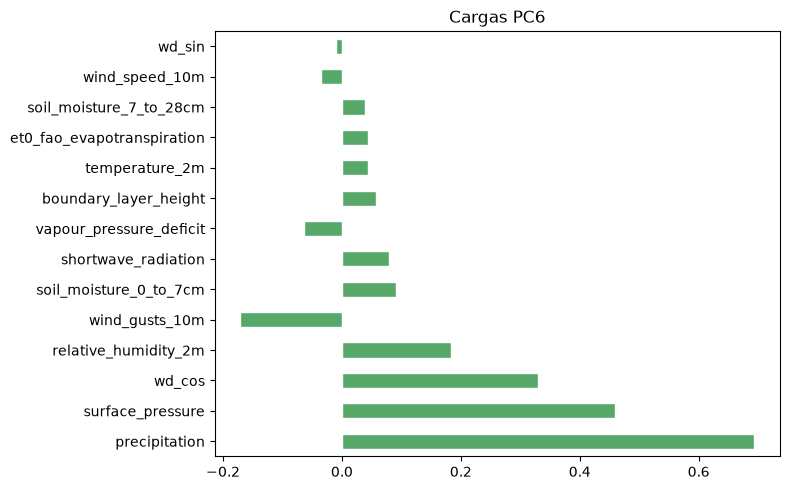


Cargas PC7 (ordenadas por |carga|):
wd_cos                        0.570969
wd_sin                       -0.485752
surface_pressure             -0.327025
wind_speed_10m               -0.130688
temperature_2m               -0.130598
boundary_layer_height         0.127853
precipitation                -0.105409
shortwave_radiation           0.091255
wind_gusts_10m               -0.077750
soil_moisture_0_to_7cm        0.067228
vapour_pressure_deficit      -0.058404
relative_humidity_2m         -0.050178
soil_moisture_7_to_28cm       0.035913
et0_fao_evapotranspiration    0.026731


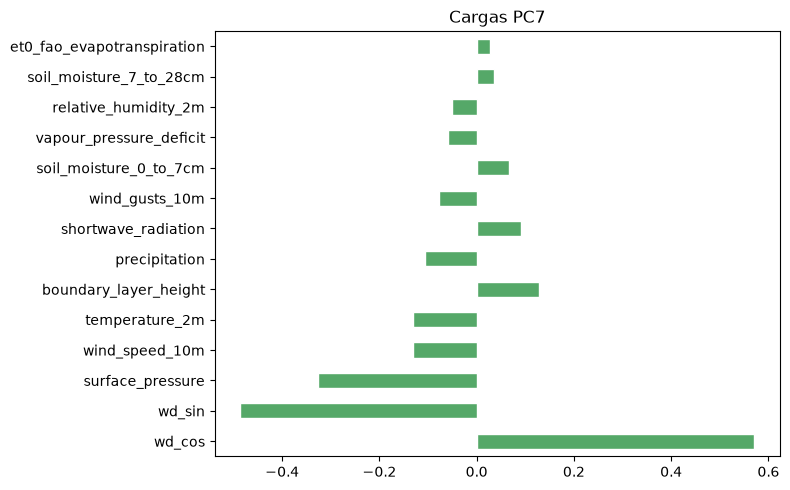

corr(PC1, indice_meteorologico) = 0.919
corr(PC1, indice_riesgo_meteo_log) = 0.827


In [4]:
# PCA de las variables meteorologicas (exploratorio) / Weather PCA (exploratory)
#
# 14 features: 12 variables continuas crudas + wd_sin/wd_cos (expansion de la
# direccion circular wind_direction_10m; la columna cruda no entra tal cual).
# Excluidas: rain (= precipitation), is_day (binaria, recodifica daynight) y los
# indices derivados (potencial_propagacion, indice_riesgo_meteo[_log],
# estres_termico_vegetacion, indice_meteorologico): se correlacionan con los PCs
# despues para interpretarlos, no entran al PCA.
# Preproceso dentro del pipeline: mediana, log1p solo en precipitation,
# z-score. k = primeros PCs con varianza acumulada >= pca.target_variance
# (configs/project.yaml; regla 80-90% + scree). Exploratorio: ajuste sobre el
# marco completo; para modelado futuro re-ajustar solo sobre train.


df_pca = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")
target = load_target_variance()
result = fit_weather_pca(df_pca, target_variance=target)

print(f"Features: {len(result.feature_names)}")
print(f"target_variance={target} -> k={result.n_components} componentes")
var_table = pd.DataFrame({
    "varianza": result.variance_ratio,
    "acumulada": np.cumsum(result.variance_ratio),
}, index=[f"PC{i + 1}" for i in range(len(result.variance_ratio))])
display(var_table)

# Scree + varianza acumulada
fig, ax1 = plt.subplots(figsize=(9, 4))
pcs = np.arange(1, len(result.variance_ratio) + 1)
ax1.bar(pcs, result.variance_ratio, color="#4C72B0", edgecolor="white")
ax1.set(xlabel="Componente", ylabel="Varianza explicada", title="Scree plot (PCA meteorologico)")
ax2 = ax1.twinx()
ax2.plot(pcs, np.cumsum(result.variance_ratio), color="#C44E52", marker="o")
ax2.axhline(target, color="grey", linestyle="--", linewidth=1)
ax2.set_ylabel("Varianza acumulada")
fig.tight_layout()
plt.show()

# Cargas de cada componente retenido (top contribuyentes): recorre PC1..PCk,
# donde k es el numero de componentes necesarios para alcanzar el umbral
# pca.target_variance (configs/project.yaml)
for i in range(result.n_components):
    pc = f"PC{i + 1}"
    top = result.loadings[pc].sort_values(key=abs, ascending=False)
    print(f"\nCargas {pc} (ordenadas por |carga|):")
    print(top.to_string())
    top.plot(kind="barh", figsize=(8, 5), color="#55A868", edgecolor="white")
    plt.title(f"Cargas {pc}")
    plt.tight_layout()
    plt.show()

# Validacion contra indices derivados (no entraron al PCA)
for col in ["indice_meteorologico", "indice_riesgo_meteo_log"]:
    if col in df_pca.columns:
        corr = result.scores["PC1"].corr(pd.to_numeric(df_pca[col], errors="coerce"))
        print(f"corr(PC1, {col}) = {corr:.3f}")


Lo que ves: con 14 variables meteorológicas bastan 7 componentes para guardar el 90,9 % de la información (tabla + curva scree: el codo). Cada gráfico de barras dice qué pesa en cada componente: el PC1 es calor-sequedad (ET0, VPD, temperatura, humedad en negativo, radiación). Las dos correlaciones cierran el círculo: el PC1 y el índice compuesto miden casi lo mismo (0,916) — usar los dos sería contar dos veces. Conclusión: el clima de estos fuegos cabe en 7 números, y el primero manda.

# 5 — Virulencia y geografía

FRP como medida de virulencia: reparto por CCAA, brecha de esfuerzo, mapa y termodinámica.

### 5.1 — FRP por CCAA/confianza y esfuerzo

Boxplots de virulencia (top-25% FRP) y barras de esfuerzo medio.

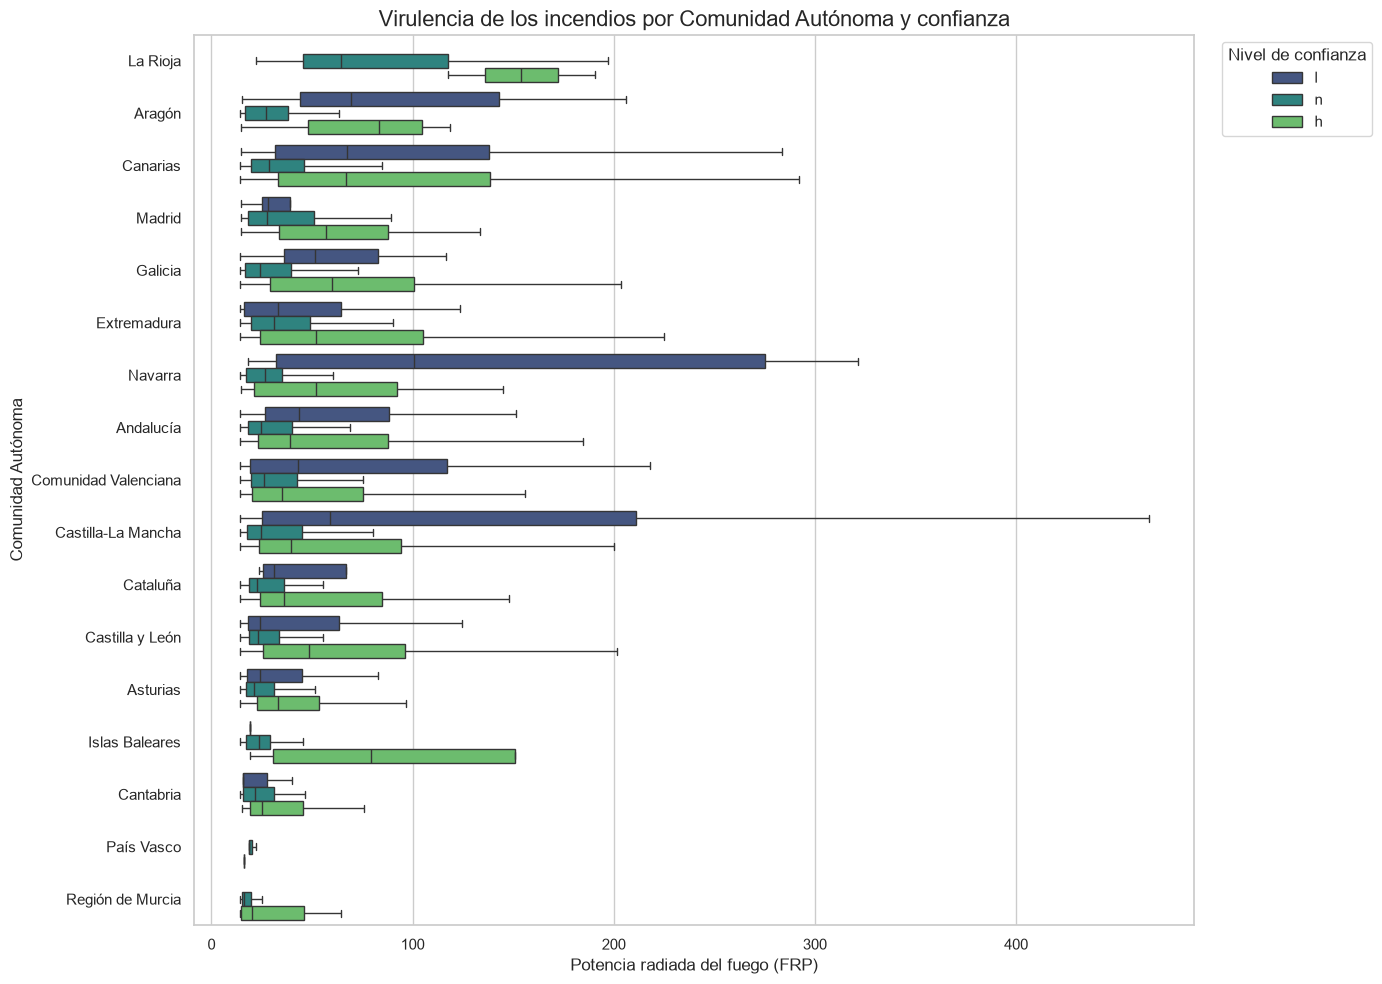

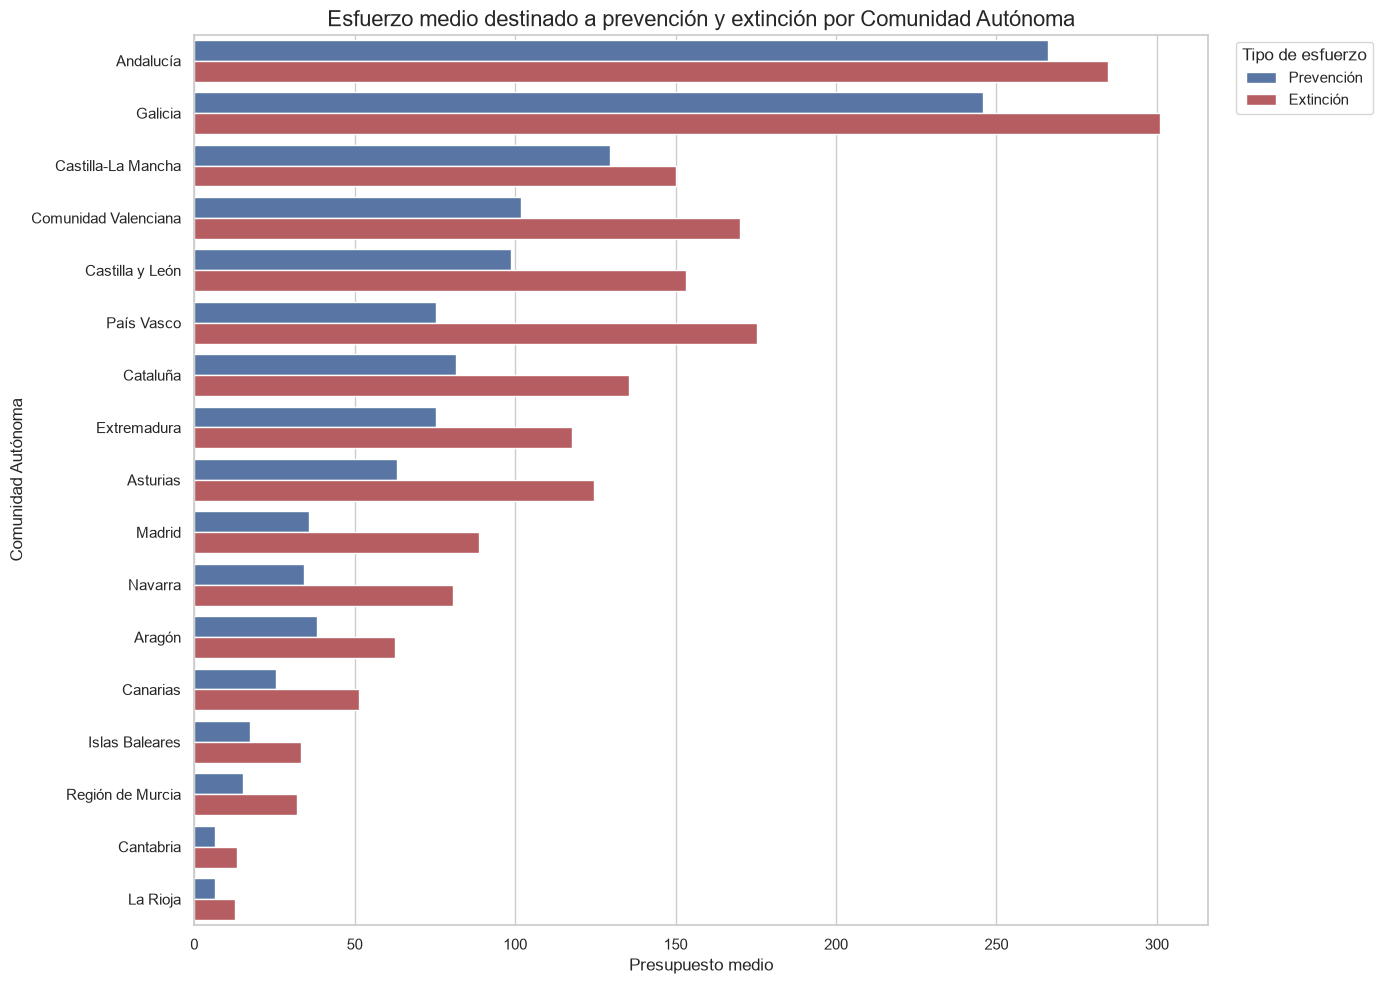

In [5]:

sns.set_theme(style="whitegrid")

# ============================================================
# 1. Virulencia por Comunidad Autónoma y Nivel de Confianza
# ============================================================

virulence_columns = [
    "ccaa",
    "frp",
]

confidence_column = None

for candidate in ["confidence_cat", "confidence_og_cat"]:
    if candidate in df.columns and df[candidate].notna().any():
        confidence_column = candidate
        break

if confidence_column is None and "confidence_num" in df.columns:
    df["confidence_level"] = pd.cut(
        df["confidence_num"],
        bins=[-np.inf, 33, 66, np.inf],
        labels=["Bajo", "Medio", "Alto"],
        include_lowest=True,
    )
    confidence_column = "confidence_level"

if confidence_column is None:
    raise KeyError(
        "No se encontró una variable de confianza válida. "
        "Se esperaba confidence_cat, confidence_og_cat o confidence_num."
    )

virulence_df = (
    df[virulence_columns + [confidence_column]]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["ccaa", "frp", confidence_column])
    .copy()
)

frp_percentile_75 = virulence_df["frp"].quantile(0.75)

virulence_df = virulence_df[
    virulence_df["frp"] > frp_percentile_75
]

if virulence_df.empty:
    raise ValueError(
        "No hay registros con FRP superior al percentil 75."
    )

confidence_order = [
    category
    for category in ["Bajo", "Medio", "Alto", "l", "n", "h"]
    if category in virulence_df[confidence_column].astype(str).unique()
]

if not confidence_order:
    confidence_order = sorted(
        virulence_df[confidence_column].astype(str).unique()
    )

virulence_df[confidence_column] = (
    virulence_df[confidence_column].astype(str)
)

ccaa_order_virulence = (
    virulence_df.groupby("ccaa")["frp"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(14, 10))

sns.boxplot(
    data=virulence_df,
    x="frp",
    y="ccaa",
    hue=confidence_column,
    order=ccaa_order_virulence,
    hue_order=confidence_order,
    palette="viridis",
    showfliers=False,
)

plt.title(
    "Virulencia de los incendios por Comunidad Autónoma y confianza",
    fontsize=16,
)
plt.xlabel("Potencia radiada del fuego (FRP)")
plt.ylabel("Comunidad Autónoma")
plt.legend(
    title="Nivel de confianza",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()
plt.show()


# ============================================================
# 2. Esfuerzo medio en prevención y extinción por zona
# ============================================================
num_years = load_config()["ccaa"]["budget_lookback_years"]

effort_columns = [
    "ccaa",
    f"extinction_prev{num_years}",
    f"prevention_prev{num_years}",
]

effort_df = (
    df[effort_columns]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=effort_columns)
    .copy()
)

if effort_df.empty:
    raise ValueError(
        "No hay registros válidos para analizar la inversión "
        "en prevención y extinción."
    )

effort_by_ccaa = (
    effort_df.groupby("ccaa", as_index=False)
    .agg(
        prevention_mean=(f"prevention_prev{num_years}", "mean"),
        extinction_mean=(f"extinction_prev{num_years}", "mean"),
    )
)

effort_by_ccaa["total_effort"] = (
    effort_by_ccaa["prevention_mean"]
    + effort_by_ccaa["extinction_mean"]
)

effort_by_ccaa = effort_by_ccaa.sort_values(
    "total_effort",
    ascending=False,
)

effort_long = effort_by_ccaa.melt(
    id_vars=["ccaa", "total_effort"],
    value_vars=["prevention_mean", "extinction_mean"],
    var_name="effort_type",
    value_name="mean_budget",
)

effort_long["effort_type"] = effort_long["effort_type"].map(
    {
        "prevention_mean": "Prevención",
        "extinction_mean": "Extinción",
    }
)

ccaa_order_effort = effort_by_ccaa["ccaa"].tolist()

plt.figure(figsize=(14, 10))

sns.barplot(
    data=effort_long,
    x="mean_budget",
    y="ccaa",
    hue="effort_type",
    order=ccaa_order_effort,
    hue_order=["Prevención", "Extinción"],
    palette=["#4C72B0", "#C44E52"],
    errorbar=None,
)

plt.title(
    "Esfuerzo medio destinado a prevención y extinción por Comunidad Autónoma",
    fontsize=16,
)
plt.xlabel("Presupuesto medio")
plt.ylabel("Comunidad Autónoma")
plt.legend(
    title="Tipo de esfuerzo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()
plt.show()


Dos figuras: (1) cajas de FRP por comunidad, sin puntos raros para ver el bulto, ordenadas por mediana — enseñan dónde se arde más fiero de media; el color es la confianza del sensor, no del fuego. (2) barras de presupuesto medio: prevención frente a extinción por comunidad. Lectura conjunta: cuánto se gasta y en qué no explica por sí solo dónde se arde más fiero.

### 5.2 — Brecha extinción–prevención

Diferencia media de esfuerzo por CCAA con línea de equilibrio.

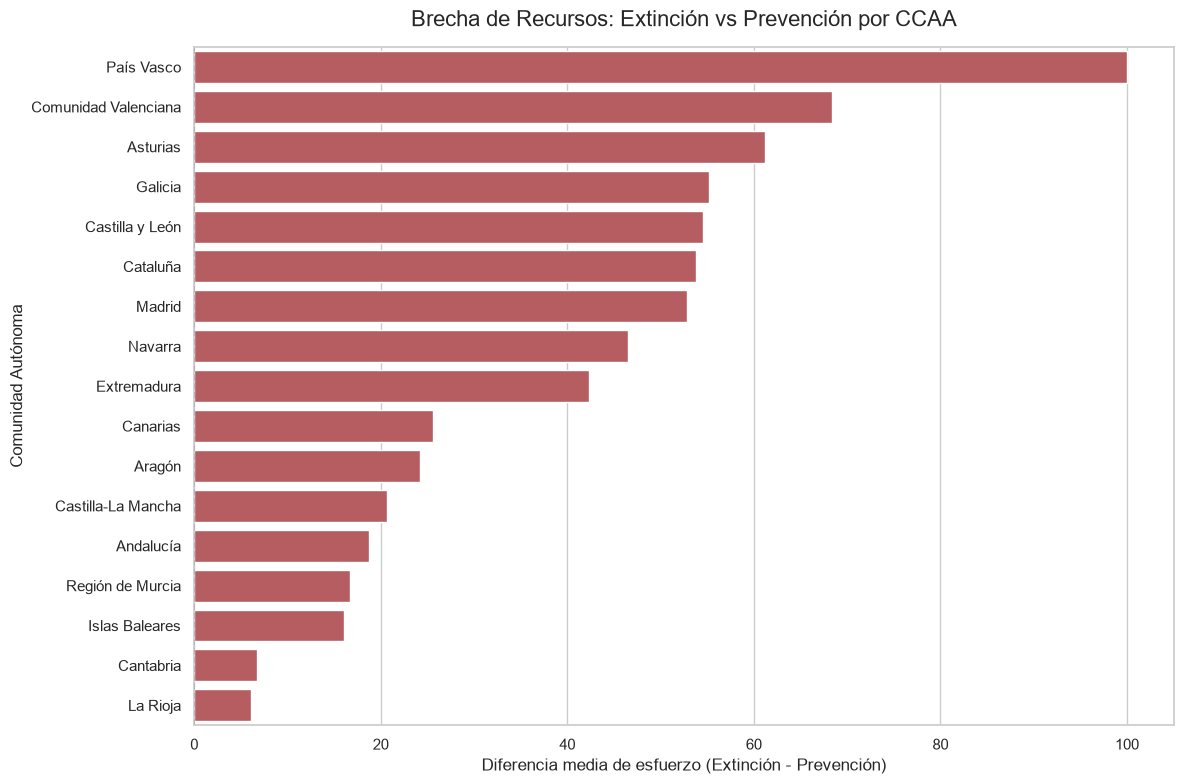

In [6]:

# 1. Agrupación por Comunidad Autónoma y cálculo de medias
num_years = load_config()["ccaa"]["budget_lookback_years"]

brecha_df = (
    df[["ccaa", f"prevention_prev{num_years}", f"extinction_prev{num_years}"]]
    .dropna()
    .groupby("ccaa", as_index=False)
    .agg(
        sum_prevention=(f"prevention_prev{num_years}", "mean"),
        sum_extinction=(f"extinction_prev{num_years}", "mean"),
    )
)

# 2. Cálculo de la brecha de esfuerzo
brecha_df["brecha_extincion"] = (
    brecha_df["sum_extinction"]
    - brecha_df["sum_prevention"]
)

# 3. Ordenación de mayor a menor brecha
brecha_df = brecha_df.sort_values(
    by="brecha_extincion",
    ascending=False,
).reset_index(drop=True)

# Clasificación para aplicar colores condicionales
brecha_df["tipo_brecha"] = brecha_df["brecha_extincion"].apply(
    lambda value: (
        "Brecha positiva: mayor esfuerzo en extinción"
        if value > 0
        else "Brecha negativa o equilibrada: mayor esfuerzo en prevención"
    )
)

# 4. Estilo y tamaño de la figura
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 8))

# 5-6. Gráfico horizontal con paleta condicional
sns.barplot(
    data=brecha_df,
    x="brecha_extincion",
    y="ccaa",
    hue="tipo_brecha",
    dodge=False,
    palette={
        "Brecha positiva: mayor esfuerzo en extinción": "#C44E52",
        "Brecha negativa o equilibrada: mayor esfuerzo en prevención": "#4C72B0",
    },
    errorbar=None,
    legend=False,
)

# 7. Línea de equilibrio
plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.2,
)

# 8. Títulos y etiquetas académicas
plt.title(
    "Brecha de Recursos: Extinción vs Prevención por CCAA",
    fontsize=16,
    pad=15,
)

plt.xlabel(
    "Diferencia media de esfuerzo (Extinción - Prevención)",
    fontsize=12,
)

plt.ylabel(
    "Comunidad Autónoma",
    fontsize=12,
)

plt.tight_layout()
plt.show()


Cada barra es lo que una comunidad gasta de más en extinción frente a prevención (rojo: más extinción; azul: más prevención; la línea del cero es el equilibrio). Lectura: casi todas cargan a extinción — se paga más por apagar que por prevenir. Es contexto, no causalidad: gastar más en extinción también refleja que arde más.

### 5.3 — Mapa de grandes incendios

Top-15% FRP en lon/lat coloreado por VPD y tamaño por FRP.

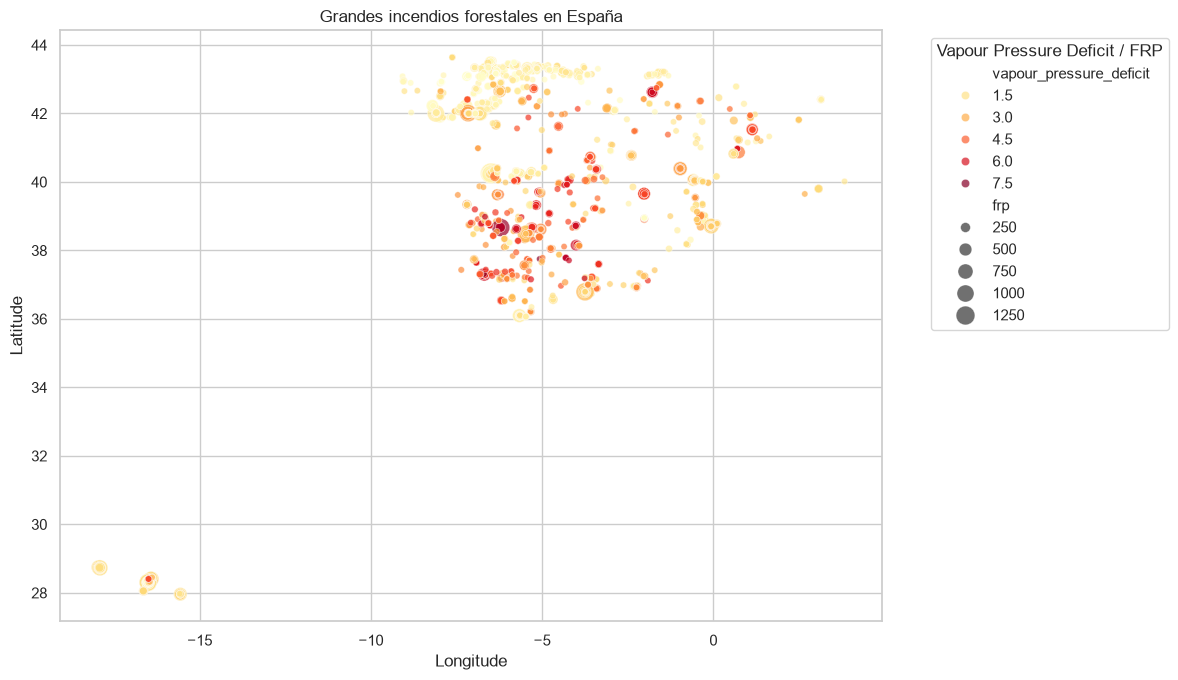

In [7]:

required_columns = [
"longitude",
"latitude",
"frp",
"vapour_pressure_deficit",
]

df_copy = df.dropna(subset=required_columns)

frp_percentile_85 = df_copy["frp"].quantile(0.85)
df_filtered = df_copy[df_copy["frp"] > frp_percentile_85]

plt.figure(figsize=(12, 9))

sns.scatterplot(
data=df_filtered,
x="longitude",
y="latitude",
hue="vapour_pressure_deficit",
palette="YlOrRd",
size="frp",
sizes=(20, 200),
alpha=0.7,
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Grandes incendios forestales en España")
plt.legend(title="Vapour Pressure Deficit / FRP", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.show()


Cada punto es una detección del 15 % más virulento: tamaño = FRP, color = sequedad del aire (amarillo = aire muy seco). Lo que se busca: si los puntos grandes y amarillos se apelotonan en zonas y fechas (episodios) o salpican por el mapa (colas estructurales).

### 5.4 — Suelo CLC vs FRP + Kruskal-Wallis

Boxplot por clase CLC (FRP>5) y test no paramétrico entre suelos.

C:\Users\Jorge\AppData\Local\Temp\ipykernel_43564\2557480690.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


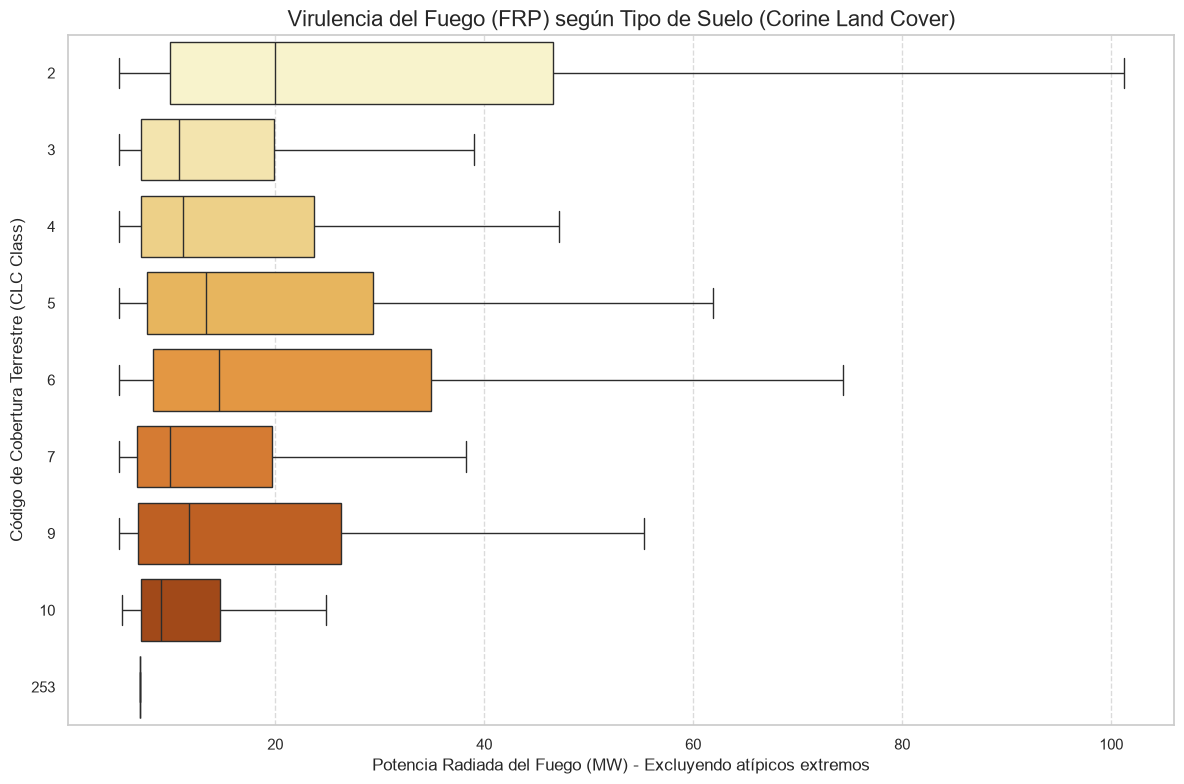

--- RESULTADOS DEL TEST DE HIPÓTESIS ---
Estadístico H: 1285.97
P-valor: 2.5368e-272
Veredicto: Se RECHAZA la hipótesis nula. El tipo de suelo AFECTA significativamente a la virulencia (FRP).


In [8]:
# ============================================================
# 6. Impacto por tipo de suelo (Corine Land Cover) vs Virulencia
# ============================================================

# Filtramos para quitar los fuegos minúsculos (agrícolas) y ver el comportamiento forestal real
df_clc = df[df["frp"] > 5].copy()
df_clc = df_clc.dropna(subset=["clc_class", "frp"])
df_clc["clc_class"] = df_clc["clc_class"].astype(str)

# Ordenamos las clases numéricamente para que el eje tenga sentido lógico
clc_order = sorted(
    df_clc["clc_class"].unique(),
    key=lambda value: float(value) if value.replace(".", "", 1).isdigit() else 999
)

plt.figure(figsize=(12, 8))

# Usamos un boxplot horizontal (orient="h") para que las categorías se lean perfectamente
sns.boxplot(
    data=df_clc,
    x="frp",
    y="clc_class",
    order=clc_order,
    palette="YlOrBr",
    showfliers=False, # Ocultamos los outliers extremos para que la caja principal sea visible
    orient="h"
)

plt.title("Virulencia del Fuego (FRP) según Tipo de Suelo (Corine Land Cover)", fontsize=16)
plt.xlabel("Potencia Radiada del Fuego (MW) - Excluyendo atípicos extremos", fontsize=12)
plt.ylabel("Código de Cobertura Terrestre (CLC Class)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Test de Hipótesis (Kruskal-Wallis) sobre el Tipo de Suelo (no paramétrico)
# ============================================================

# Filtramos valores nulos para el test
df_test = df.dropna(subset=['clc_class', 'frp']).copy()

# Agrupamos los valores de FRP en listas separadas por cada clase de suelo
grupos_clc = [grupo["frp"].values for nombre, grupo in df_test.groupby("clc_class")]

# Aplicamos el test de Kruskal-Wallis (ANOVA no paramétrico)
stat, p_valor = stats.kruskal(*grupos_clc)

print("--- RESULTADOS DEL TEST DE HIPÓTESIS ---")
print(f"Estadístico H: {stat:.2f}")
print(f"P-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("Veredicto: Se RECHAZA la hipótesis nula. El tipo de suelo AFECTA significativamente a la virulencia (FRP).")
else:
    print("Veredicto: No se puede rechazar la hipótesis nula. El tipo de suelo no parece afectar estadísticamente.")


Cajas de FRP por tipo de suelo más el test de Kruskal-Wallis. El test pregunta si el suelo 'mueve' la virulencia: H = 1503,7 con p ≈ 0 significa que sí, y con contundencia — no es azar. Conclusión: el uso del suelo contiene señal real y merece entrar en el clustering (conjunto C).

### 5.5 — VPD vs humedad

Scatter humedad×VPD coloreado por temperatura (muestra de 2000).

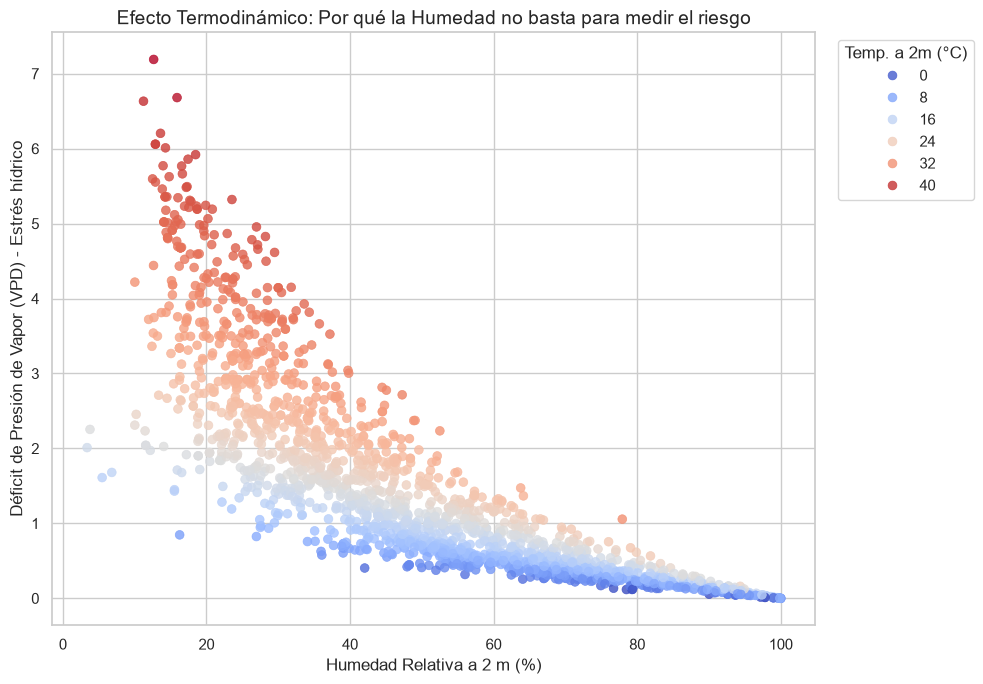

In [9]:
# ============================================================
# 7. Relación Termodinámica: VPD vs Humedad Relativa
# ============================================================

# Muestreo para evitar crasheos (2000 puntos son suficientes para dibujar la curva)
sample_size = 2000
if len(df) > sample_size:
    thermo_sample = df.sample(n=sample_size, random_state=42)
else:
    thermo_sample = df

plt.figure(figsize=(10, 7))

# Cruzamos Humedad y VPD, coloreando por Temperatura para ver el efecto exponencial
scatter = sns.scatterplot(
    data=thermo_sample,
    x="relative_humidity_2m",
    y="vapour_pressure_deficit",
    hue="temperature_2m",
    palette="coolwarm", # Azul para frío, rojo para calor
    alpha=0.8,
    edgecolor=None,
    s=40
)

plt.title("Efecto Termodinámico: Por qué la Humedad no basta para medir el riesgo", fontsize=14)
plt.xlabel("Humedad Relativa a 2 m (%)")
plt.ylabel("Déficit de Presión de Vapor (VPD) - Estrés hídrico")

# Ajustamos la leyenda
plt.legend(
    title="Temp. a 2m (°C)", 
    bbox_to_anchor=(1.02, 1), 
    loc="upper left"
)

plt.tight_layout()
plt.show()

Cada punto es una detección: humedad en x, déficit de vapor en y, color = temperatura. La diagonal es física pura: calor↔seco, frío↔húmedo, y el color corre a lo largo de ella. Lectura: VPD y humedad cuentan casi la misma historia al revés — por eso el PCA las funde en un solo eje.